# Case study: an N-back task

This notebook analyses one recording from start to end: loading the data, adding the behavioural log to the events, preprocessing, the tonic pupil size per condition and event-related pupil dilations (ERPDs). The individual steps are explained in more detail in the tutorials on [blinks](blinks.ipynb), [event metadata](event_metadata.ipynb) and [ERPDs](erpds.ipynb).

The data are from one participant doing an N-back task for about 56 minutes (EyeLink, both eyes, 1000 Hz). In each trial, a fixation cross is followed by a digit, and the participant presses a button if the digit is a *target*. There are four kinds of blocks:

- `0b`, `1b`, `2b`: 0-back, 1-back and 2-back blocks with increasing working-memory load (in the 2-back task, a digit is a target if it is the same as the one two trials before)
- `p`: blocks without targets (the participant responded in only a few of these trials)

The experiment had three runs with a grey, a black and a white screen background. Each run started with an adaptation period and contained one block of each kind (110 trials per block).

The data are stored on [figshare](https://figshare.com/articles/dataset/Example_pypillometry_dataset/28776617). This notebook goes through all steps of reading them; `pp.get_example_data("nback_001")` does the same in one line.

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pp.logging_set_level("WARNING")  # no messages about the steps

## Reading the data

The figshare item contains the data of several recordings. `get_figshare_files()` lists its files, with their size and download link:

In [2]:
figshare_id = 28776617
files = pp.get_figshare_files(figshare_id, version=1)
list(files)

['001_labtest_events.asc',
 '001_rlmw_events.asc',
 '001_rlmw_samples.asc',
 '002_rlmw_events.asc',
 '002_rlmw_samples.asc',
 '003_rlmw_events.asc',
 '003_rlmw_samples.asc',
 'sub-001_ses-1.csv',
 'sub-001_ses-1.pypil']

For this recording, there are two files: the eye-tracking data, already converted to a pypillometry file (`.pypil`), and the behavioural log of the experiment (`.csv`). `fetch_figshare_file()` downloads them into the folder `example_data` (and uses the local copies when the notebook is run again):

EyeData(sub-001_ses-1, 229.0MiB):
 n                 : 3387223
 sampling_rate     : 1000.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 2870
 experimental_setup: {'screen_resolution': (1280, 1024), 'physical_screen_size_mm': None, 'eye_to_screen_distance_mm': 'not set', 'camera_position': 'not set'}
 calibration       : {'left': {'n': 9, 'mean': 0.1978, 'sd': 0.1252, 'max': 0.39, 'min': 0.02}, 'right': {'n': 9, 'mean': 0.3478, 'sd': 0.1871, 'max': 0.75, 'min': 0.1}}
 duration_minutes  : 56.4537
 start_min         : 0.0
 end_min           : 56.4537
 params            : {}
 nblinks           : {}
 blinks            : {}
 glimpse           : EyeDataDict(vars=6,n=3387223,shape=(3387223,)): 
  left_x (float64): 656.0, 656.2, 655.8, 657.6, 655.6...
  left_y (float64): 510.7, 511.2, 510.0, 509.4, 509.3...
  left_pupil (float64): 1032.0, 1031.0, 1030.0, 1029.0, 1031.0...
  right_x (float64): 650.9, 652.4, 652.4, 650.0, 649.9...
  right_y (float64): 473.4, 474.3, 475.4, 474.2, 474.3...
  right_pupil (float64): 1108.0, 1103.0, 1106.0, 1103.0, 1101.0...

 Info: 1 keys: eyelink_info
 History:
 *
 └ set_events(Events(2870))
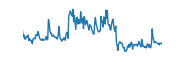
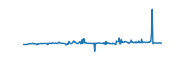
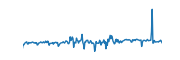
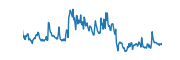
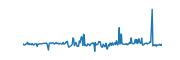
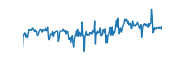

In [3]:
fname_data = pp.fetch_figshare_file(figshare_id, "sub-001_ses-1.pypil", version=1,
                                    cache_dir="example_data")
fname_log = pp.fetch_figshare_file(figshare_id, "sub-001_ses-1.csv", version=1,
                                   cache_dir="example_data")

d = pp.EyeData.from_file(fname_data)
d

## Events and behavioural data

The experiment sent an event to the eye tracker at the fixation cross, the stimulus and the response of each trial. The labels contain the run, the screen background, the block, the task and the trial:

In [4]:
list(d.events.labels[4:10])

[np.str_('run-1_scr-grey_block-1_task-0b_trial-1_fix'),
 np.str_('run-1_scr-grey_block-1_task-0b_trial-1_stim_target-1'),
 np.str_('run-1_scr-grey_block-1_task-0b_trial-1_resp_acc-1'),
 np.str_('run-1_scr-grey_block-1_task-0b_trial-2_fix'),
 np.str_('run-1_scr-grey_block-1_task-0b_trial-2_stim_target-0'),
 np.str_('run-1_scr-grey_block-1_task-0b_trial-3_fix')]

The behavioural log starts with a header of `# key: value` lines, followed by a table with one row per trial:

In [5]:
with open(fname_log) as f:
    print("".join(f.readlines()[:10]))

# N-back Task Log File
# Generated by: nback_task_final.py
# Session Date: 2026-05-04 10:09:33
# Subject ID: 001
# Session Number: 1
# Ambient Light: High
#
subj,session,ambient,run,screen,block,task,trial,stimulus,target,response,accuracy,rt,fix_onset,stim_onset,resp_onset
001,1,High,1,grey,1,0b,1,3,1,1,1,0.7072089998982847,131.68815430020913,132.34229509998113,133.0559440003708
001,1,High,1,grey,1,0b,2,7,0,0,1,,133.75420200033113,134.58102420018986,



We keep the header in the `info` of the dataset and read the table with pandas (`comment="#"` skips the header):

In [6]:
with open(fname_log) as f:
    comments = [line.lstrip("# ").strip() for line in f if line.startswith("#")]
d.info["behaviour_log"] = dict(c.split(": ", 1) for c in comments if ": " in c)

log = pd.read_csv(fname_log, comment="#")
log.head()

,subj,session,ambient,run,screen,block,task,trial,stimulus,target,response,accuracy,rt,fix_onset,stim_onset,resp_onset
0,1,1,High,1,grey,1,0b,1,3,1,1,1.0,0.707209,131.688154,132.342295,133.055944
1,1,1,High,1,grey,1,0b,2,7,0,0,1.0,NaN,133.754202,134.581024,NaN
2,1,1,High,1,grey,1,0b,3,3,1,1,1.0,0.458959,135.993416,136.510453,136.976212
3,1,1,High,1,grey,1,0b,4,4,0,0,1.0,NaN,137.922282,138.751214,NaN
4,1,1,High,1,grey,1,0b,5,0,0,0,1.0,NaN,140.170939,140.767675,NaN


The log has the digit (`stimulus`), whether it was a target, the response, its accuracy and the reaction time (`rt`, in seconds) of each trial. To use this information in the analysis of the pupil, we add it to the metadata of the events (see the [event metadata tutorial](event_metadata.ipynb)). First, `parse_labels()` turns the parts of the labels into metadata columns, one regular expression per column:

In [7]:
events = (d.events.parse_labels(r"run-(?P<run>\d+)")
                  .parse_labels(r"scr-(?P<screen>[a-z]+)")
                  .parse_labels(r"block-(?P<block>\d+)")
                  .parse_labels(r"task-(?P<task>[^_]+)")
                  .parse_labels(r"trial-(?P<trial>\d+)"))
events[2:8]

,Onset (ms),Label,run,screen,block,task,trial
0,10729.0,run-1_scr-grey_adapton,1.0,grey,NaN,,NaN
1,130730.0,run-1_scr-grey_adaptoff,1.0,grey,NaN,,NaN
2,134046.0,run-1_scr-grey_block-1_task-0b_trial-1_fix,1.0,grey,1.0,0b,1.0
3,134700.0,run-1_scr-grey_block-1_task-0b_trial-1_stim_target-1,1.0,grey,1.0,0b,1.0
4,135414.0,run-1_scr-grey_block-1_task-0b_trial-1_resp_acc-1,1.0,grey,1.0,0b,1.0
5,136112.0,run-1_scr-grey_block-1_task-0b_trial-2_fix,1.0,grey,1.0,0b,2.0


Run, block, task and trial identify a row of the log. `merge_table()` adds the columns of the matching row to all events of the trial (fixation, stimulus and response); events outside of the trials (e.g., `experiment_start`) get missing values. Finally, `set_events()` stores the events in the dataset:

In [8]:
events = events.merge_table(log, on=["run", "block", "task", "trial"],
                            columns=["stimulus", "target", "response", "accuracy", "rt"])
d = d.set_events(events)

Now each event has the information about its trial. Here are the first stimulus events as a table:

In [9]:
stim = d.events.filter("_stim")
trials = pd.DataFrame(stim.to_table())
trials.head()

,onset,label,run,screen,block,task,trial,stimulus,target,response,accuracy,rt
0,134700.0,run-1_scr-grey_block-1_task-0b_trial-1_stim_ta...,1.0,grey,1.0,0b,1.0,3.0,1.0,1.0,1.0,0.707209
1,136939.0,run-1_scr-grey_block-1_task-0b_trial-2_stim_ta...,1.0,grey,1.0,0b,2.0,7.0,0.0,0.0,1.0,NaN
2,138868.0,run-1_scr-grey_block-1_task-0b_trial-3_stim_ta...,1.0,grey,1.0,0b,3.0,3.0,1.0,1.0,1.0,0.458959
3,141109.0,run-1_scr-grey_block-1_task-0b_trial-4_stim_ta...,1.0,grey,1.0,0b,4.0,4.0,0.0,0.0,1.0,NaN
4,143125.0,run-1_scr-grey_block-1_task-0b_trial-5_stim_ta...,1.0,grey,1.0,0b,5.0,0.0,0.0,0.0,1.0,NaN


With one stimulus event per trial, this table is also a summary of the behaviour. Accuracy decreases with the load, from almost perfect in the 0-back task to about 83% in the 2-back task. The reaction times are the times of the responses; there are no targets in the `p` blocks, and the participant responded in only 13 of their 330 trials.

In [10]:
trials.groupby("task").agg(trials=("trial", "size"), targets=("target", "sum"),
                           accuracy=("accuracy", "mean"), rt=("rt", "mean"))

,trials,targets,accuracy,rt
task,,,,
0b,330,81.0,0.996970,0.527712
1b,330,81.0,0.975758,0.665249
2b,330,81.0,0.827273,0.891507
p,330,0.0,NaN,0.571454


## Breaks and adaptation periods

Not all of the recording is part of the analysis: each run starts with a two-minute adaptation period (from the event `adapton` to `adaptoff`), in which the participant looked at the new background, and there are short breaks between the blocks. There is no event at the end of a block, but every block has 110 trials, so a block runs from the fixation cross of trial 1 to the stimulus of trial 110. `get_intervals()` finds these spans; we extend them by 1 s before the first fixation cross and 3 s after the last stimulus, so that the response and the time window of the ERPDs below are included:

In [11]:
blocks = d.get_intervals(start="trial-1_fix", end="trial-110_stim", window=(-1, 3) * u.sec)
blocks.to_units("min").as_pandas()[["run", "screen", "task", "start", "end"]]

,run,screen,task,start,end
0,1.0,grey,0b,2.217433,6.156100
1,1.0,grey,1b,6.382417,10.303750
2,1.0,grey,2b,10.591267,14.511000
3,1.0,grey,p,14.631717,18.560167
4,2.0,black,p,20.758383,24.661550
5,2.0,black,0b,25.076833,29.019733
6,2.0,black,2b,29.485550,33.454133
7,2.0,black,1b,33.841583,37.787717
8,3.0,white,0b,39.994133,43.946850
9,3.0,white,p,44.048050,47.965600


`keep_intervals()` excludes everything outside of the blocks. Unlike blinks, excluded periods are not treated as missing data: the preprocessing below does not interpolate across them, and all analyses ignore them (see [excluded periods](../user_guide/data_model.rst#excluded-periods)):

In [12]:
d = d.keep_intervals(blocks)
print(f"excluded: {d.excluded_duration('min'):.1f} of {d.tx[-1] / 60000:.1f} minutes")

excluded: 9.2 of 56.5 minutes


## Preprocessing

A minute of the raw data shows a problem of this recording: the participant blinked in almost every trial, and during the blinks the eye tracker recorded values around 200 instead of losing the pupil completely (probably because the eyelid covered part of the pupil):

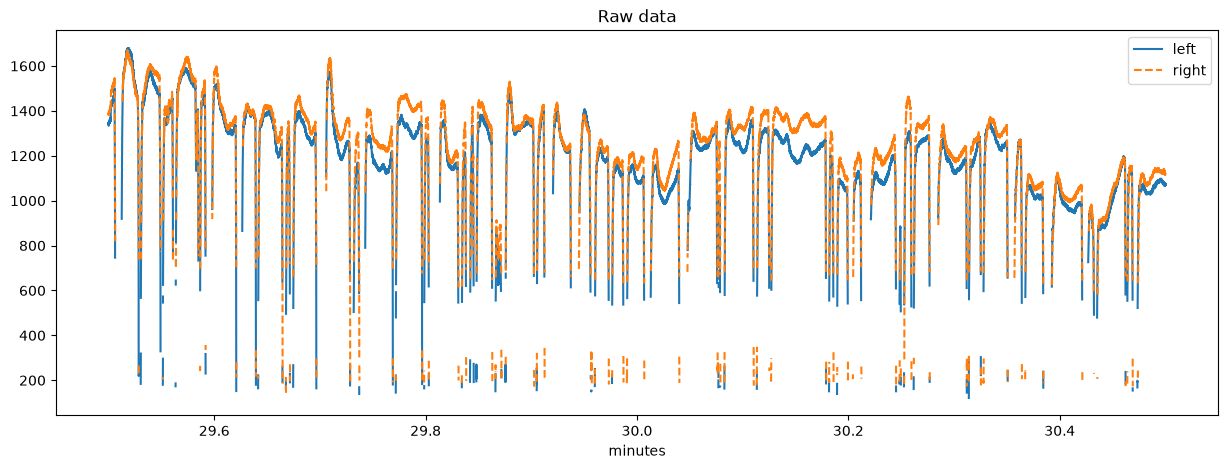

In [13]:
fig, ax = plt.subplots(figsize=(15, 5))
d.plot.plot_pupil((29.5, 30.5) * u.min, units="min", show_events=False, show_blinks=False,
                  title="Raw data", ax=ax);

The blink detection finds these dips with its "velocity" strategy (the fast drop and recovery of the signal), in addition to the samples where the pupil was lost. We interpolate the blinks, filter the signal with a 5 Hz low-pass filter and downsample it to 50 Hz (see the [blinks tutorial](blinks.ipynb)). Some gaps are long (the pupil was lost for up to 8 s), and the default cubic interpolation overshoots over such gaps, so we use linear interpolation. Finally, the two eyes are averaged into a new eye `mean`:

pp: 14:52:36 | WARNING  | blinks_interpolate:846 | Skipping blink 186 for left: no usable data at its anchor points (t1=617083, t2=617729, t3=618375, t4=619021)


pp: 14:52:36 | WARNING  | blinks_interpolate:846 | Skipping blink 187 for left: no usable data at its anchor points (t1=635351, t2=635743, t3=636135, t4=636527)


pp: 14:52:36 | WARNING  | blinks_interpolate:846 | Skipping blink 290 for left: no usable data at its anchor points (t1=869634, t2=870222, t3=870810, t4=871398)


pp: 14:52:36 | WARNING  | blinks_interpolate:846 | Skipping blink 611 for left: no usable data at its anchor points (t1=2006417, t2=2007012, t3=2007607, t4=2008202)


pp: 14:52:36 | WARNING  | blinks_interpolate:846 | Skipping blink 697 for left: no usable data at its anchor points (t1=2398626, t2=2399604, t3=2403095, t4=2403480)


pp: 14:52:36 | WARNING  | blinks_interpolate:846 | Skipping blink 860 for left: no usable data at its anchor points (t1=2892405, t2=2892763, t3=2893121, t4=2893479)


... (2 outputs left out)

pp: 14:52:37 | WARNING  | blinks_interpolate:846 | Skipping blink 295 for right: no usable data at its anchor points (t1=869624, t2=870217, t3=870810, t4=871403)


pp: 14:52:37 | WARNING  | blinks_interpolate:846 | Skipping blink 616 for right: no usable data at its anchor points (t1=2006437, t2=2007025, t3=2007613, t4=2008201)


pp: 14:52:37 | WARNING  | blinks_interpolate:846 | Skipping blink 699 for right: no usable data at its anchor points (t1=2398600, t2=2399605, t3=2403099, t4=2403486)


pp: 14:52:37 | WARNING  | blinks_interpolate:846 | Skipping blink 861 for right: no usable data at its anchor points (t1=2892418, t2=2892761, t3=2893104, t4=2893447)


Eye,Count,Mean ± SD (ms),Range (ms)
left_pupil,1564,269.3 ± 142.5,"[40.0, 1180.0]"
right_pupil,1565,273.2 ± 149.7,"[20.0, 1300.0]"
mean_pupil,1571,256.2 ± 134.7,"[20.0, 1040.0]"

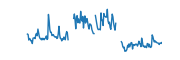
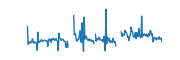
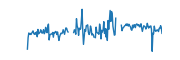
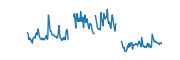
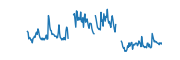
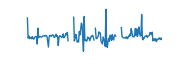
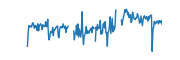

In [14]:
d = d | (pp.pupil.blinks_detect()
         | pp.pupil.blinks_merge_close(distance=100 * u.ms)
         | pp.pupil.blinks_interpolate(margin=(50, 150) * u.ms, interp_type="linear")
         | pp.pupil.lowpass_filter(cutoff=5)
         | pp.downsample(50)
         | pp.pupil.merge_eyes())
d

The warnings are about blinks at the edges of the blocks: one side of them is in an excluded period, so they are not interpolated. The same minute after preprocessing; the red background marks the interpolated periods:

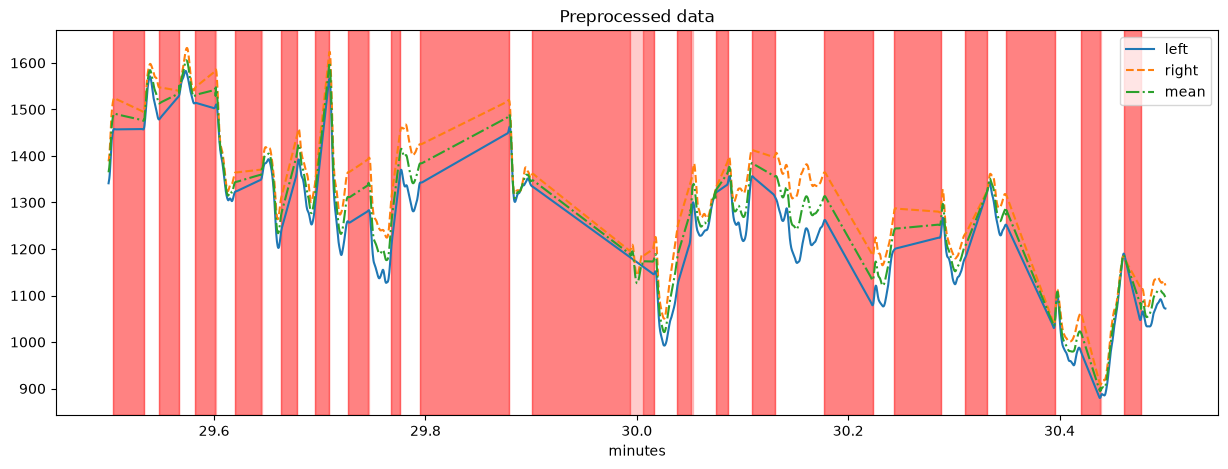

In [15]:
fig, ax = plt.subplots(figsize=(15, 5))
d.plot.plot_pupil((29.5, 30.5) * u.min, units="min", show_events=False,
                  title="Preprocessed data", ax=ax);

Because of the frequent blinks, a large part of the data is interpolated. `layer_stats()` gives the number, the duration and the percentage of the blinks and the interpolated stretches of each pupil channel (only within the blocks, the excluded periods are left out):

In [16]:
d.layer_stats(["blink", "interpolated"], variables="pupil", units="sec")

n      mean        sd   min   max  \
channel     layer                                                
left_pupil  blink         1564  0.269297  0.142546  0.04  1.18   
            interpolated  1063  0.822521  0.806094  0.26  7.78   
right_pupil blink         1565  0.273176  0.149704  0.02  1.30   
            interpolated  1066  0.834034  0.854552  0.24  7.76   
mean_pupil  blink         1571  0.256219  0.134715  0.02  1.04   
            interpolated  1071  0.804146  0.774948  0.26  7.76   

                          total_duration units    percent  
channel     layer                                          
left_pupil  blink                 421.18   sec  14.863463  
            interpolated          874.34   sec  30.855501  
right_pupil blink                 427.52   sec  15.087202  
            interpolated          889.08   sec  31.375677  
mean_pupil  blink                 402.52   sec  14.204950  
            interpolated          861.24   sec  30.393202

About 30% of the samples are interpolated, so the results below should be taken with some care. Passing `policy="strict"` to `get_segments()` and `stat_per_event()` would use the recorded samples only (see the [missing data tutorial](missing_data.ipynb)); for this recording, that leaves about 30% of each trial missing and gives much noisier curves.

## Overview of the recording

A plot of the whole preprocessed session (the averaged pupil) shows the three runs. The excluded periods are shaded; the long ones at the start of each run are the adaptation periods:

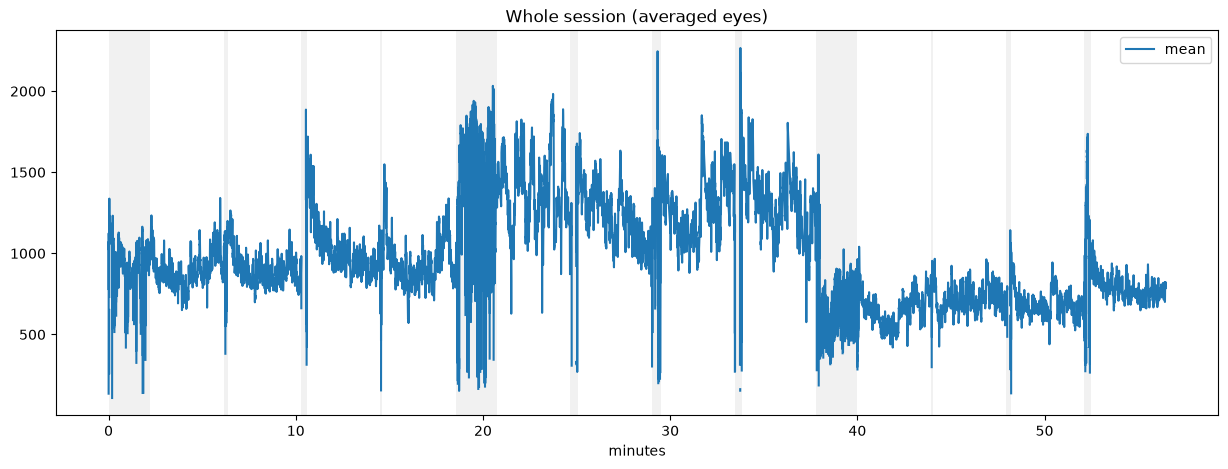

In [17]:
fig, ax = plt.subplots(figsize=(15, 5))
d.plot.plot_pupil(units="min", eyes="mean", show_events=False, show_blinks=False,
                  highlight=d.get_excluded(), highlight_color="lightgrey",
                  title="Whole session (averaged eyes)", ax=ax);

The pupil size mostly follows the brightness of the screen: it is largest in the second run (black background) and smallest in the third (white background). Any effect of the task has to be compared within a run, or relative to the pupil size in the run. In the excluded periods, the blinks were not interpolated, so the raw dips are still visible there.

## Tonic pupil size

For each trial, the mean pupil size in the 200 ms before the stimulus is the *baseline* of the trial. `stat_per_event()` computes it for the stimulus epochs, which also carry the metadata of their events:

In [18]:
baseline_epochs = d.get_epochs(stim, window=(-200, 0) * u.ms)
trials["baseline"] = d.stat_per_event(baseline_epochs, eyes="mean", variables="pupil")["mean_pupil"]

baselines = trials.pivot_table(index="screen", columns="task", values="baseline")
baselines.loc[["black", "grey", "white"], ["p", "0b", "1b", "2b"]].round()

task,p,0b,1b,2b
screen,,,,
black,1421.0,1227.0,1313.0,1282.0
grey,933.0,882.0,879.0,1008.0
white,716.0,646.0,676.0,780.0


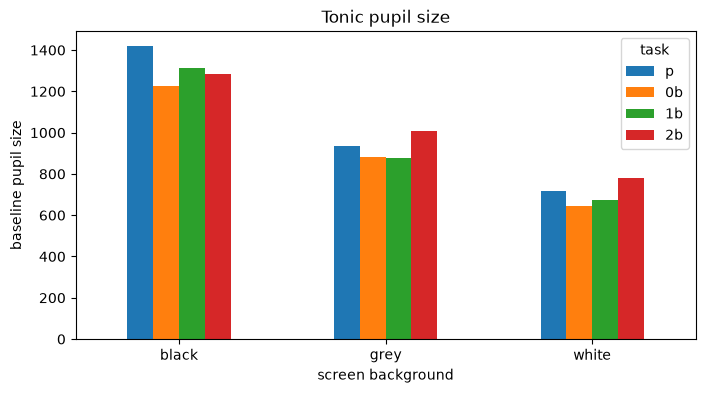

In [19]:
ax = baselines.loc[["black", "grey", "white"], ["p", "0b", "1b", "2b"]].plot.bar(figsize=(8, 4), rot=0)
ax.set(ylabel="baseline pupil size", xlabel="screen background", title="Tonic pupil size");

The background has the largest effect: the pupil is about twice as large on the black screen as on the white one. In the grey and white runs, the baseline is largest in the 2-back blocks; in the black run, it is largest in the `p` block. The order of the blocks differed between runs, so the baseline of a block also includes slow changes over time.

## Event-related pupil dilations

To look at the response to the stimuli, we cut the averaged pupil from 500 ms before to 2000 ms after each stimulus (the next trial starts about 2 s later) and subtract the baseline of each trial:

SegmentedEyeData(stimulus): 1320 segments x 125 time points (-500 to 1980 ms, 50 Hz)
  channels: mean_pupil (0.0% missing)
  epochs: Epochs 'events_1320' | 1320 epochs, window (-500, 2000) ms
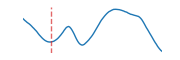

In [20]:
segments = d.get_segments(d.get_epochs(stim, window=(-500, 2000) * u.ms), "mean_pupil", name="stimulus")
segments.pupil.baseline_correct(window=(-200, 0))
segments

The segments keep the metadata of the stimulus events, so they can be selected by condition with `filter()`. Only the targets require a response, and the button press itself dilates the pupil. The left panel compares targets and non-targets, the right panel the tasks for the non-targets only:

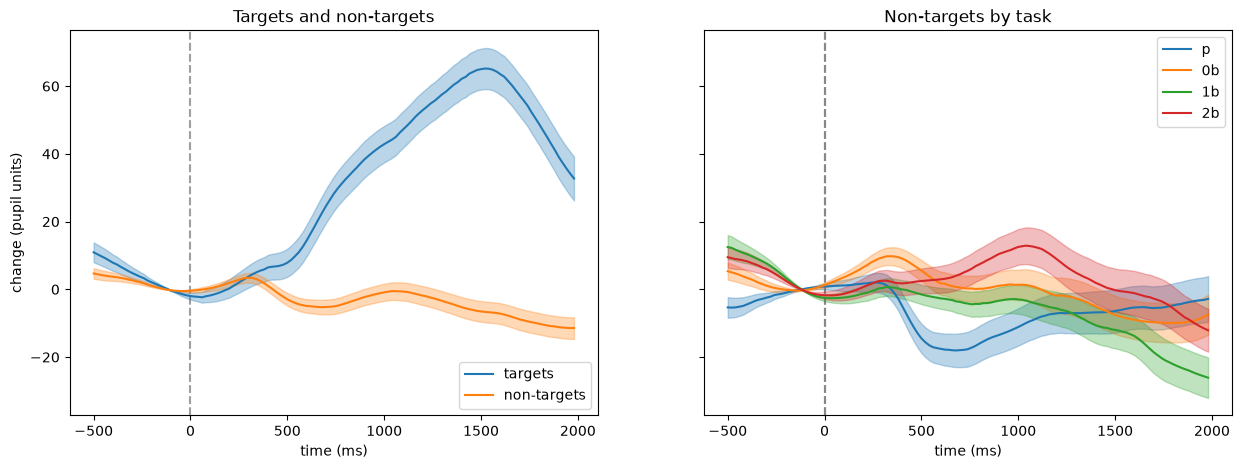

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
segments.filter(target=1).pupil.plot(ax=axs[0], label="targets")
segments.filter(target=0).pupil.plot(ax=axs[0], label="non-targets")
for task in ["p", "0b", "1b", "2b"]:
    segments.filter(target=0, task=task).pupil.plot(ax=axs[1], label=task, show_missing=False)
axs[0].set(title="Targets and non-targets", ylabel="change (pupil units)")
axs[1].set(title="Non-targets by task")
axs[0].legend()
axs[1].legend();

The targets cause a large dilation, which peaks about 1.5 s after the stimulus. The responses to non-targets are small: in the `p` blocks, the pupil constricts after the stimulus, and in the 2-back blocks, it dilates slightly, with a peak about 1 s after the stimulus.

A carpet plot shows the single trials (one row per trial), here the target trials with a response, sorted by the reaction time:

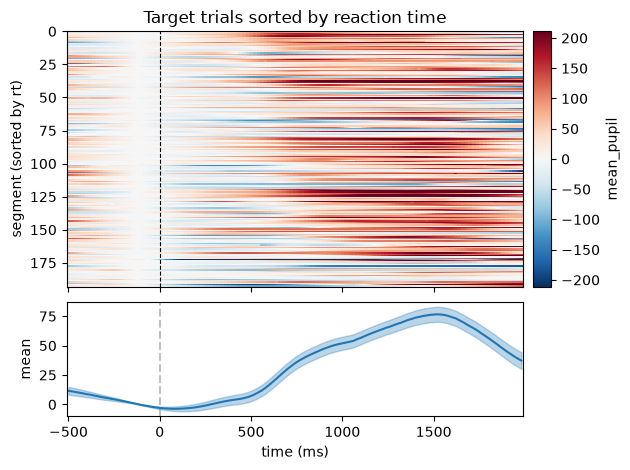

In [22]:
segments.filter(target=1, response=1).plot_carpet(sort_by="rt", show_mean=True,
                                                  title="Target trials sorted by reaction time");

In most trials, the dilation starts about 500 ms after the stimulus, without a clear relation to the reaction time. A few rows have extreme values over the whole window; these are trials with artifacts that the preprocessing did not remove.

## Screen brightness and baseline correction

The pupil size differs a lot between the backgrounds, so the same dilation in pupil units is a smaller relative change on the black screen (large pupil) than on the white screen (small pupil). With `method="percent"`, the baseline correction gives the change relative to the baseline of each trial (see [ERPDs](erpds.ipynb)):

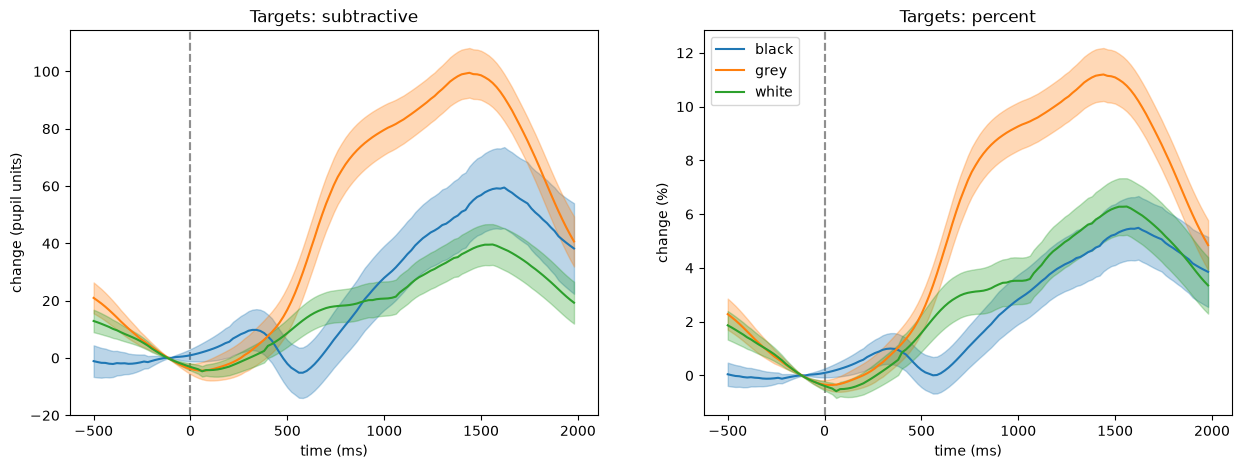

In [23]:
epochs = d.get_epochs(stim.filter(target=1), window=(-500, 2000) * u.ms)
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for screen in ["black", "grey", "white"]:
    seg = d.get_segments(epochs.filter(screen=screen), "mean_pupil")
    seg.pupil.baseline_correct(window=(-200, 0), inplace=False).pupil.plot(
        ax=axs[0], label=screen, show_missing=False)
    seg.pupil.baseline_correct(window=(-200, 0), method="percent", inplace=False).pupil.plot(
        ax=axs[1], label=screen, show_missing=False)
axs[0].set(title="Targets: subtractive", ylabel="change (pupil units)")
axs[1].set(title="Targets: percent", ylabel="change (%)")
axs[1].legend();

In pupil units, the response to targets is largest on the grey screen and smallest on the white screen. Relative to the baseline, the responses on the black and the white screen are about the same (about 6%), while the response on the grey screen is still about twice as large. The grey run was also the first one, so this could be an effect of the background or of the time in the experiment (e.g., fatigue); with one run per background, the two cannot be separated.